# Car Loan Approval – Machine Learning Practical

## Aim
Perform exploratory data analysis, train and compare the eight algorithms shown in the supplied reference, and save the best-performing category-specific model for LoanIQ V2.

**Dataset:** `car_loan_acceptance.csv` (1,200 synthetic applications)  
**Target:** `loan_approved` (1 = approved, 0 = not approved)

This is structured as a student practical: every stage explains what is being done and why. We use the following eight models: Dummy, Logistic Regression, Decision Tree, Random Forest, HistGradientBoosting, CatBoost, XGBoost and MLP. No hyperparameter search or fine-tuning is performed; fixed baseline configurations are used.

**GPU note:** CatBoost and XGBoost are configured to use GPU when CUDA is available. If this runtime has no accessible CUDA GPU, they automatically use CPU and the comparison table clearly labels that fallback.

**Data limitation:** The data and labels are synthetic. Metrics do not represent real-world bank approval performance.

## Step 1 – Import libraries and configure paths

We import tools for data handling, plotting, preprocessing, model training, evaluation and measuring training time. The path logic allows the notebook to run from either the package root or its `notebooks` directory.

In [1]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import torch
from IPython.display import display
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, log_loss, confusion_matrix, classification_report)
from catboost import CatBoostClassifier
from xgboost import XGBClassifier

# Adapter makes CatBoost compatible with the installed scikit-learn Pipeline API.
class CatBoostSklearnWrapper(ClassifierMixin, BaseEstimator):
    def __init__(self, iterations=300, depth=6, learning_rate=0.05, task_type="CPU", random_seed=42):
        self.iterations = iterations
        self.depth = depth
        self.learning_rate = learning_rate
        self.task_type = task_type
        self.random_seed = random_seed

    def fit(self, X, y):
        self.model_ = CatBoostClassifier(
            iterations=self.iterations, depth=self.depth,
            learning_rate=self.learning_rate, verbose=False,
            task_type=self.task_type, random_seed=self.random_seed
        )
        self.model_.fit(X, y)
        self.classes_ = self.model_.classes_
        return self

    def predict(self, X):
        return self.model_.predict(X).astype(int).ravel()

    def predict_proba(self, X):
        return self.model_.predict_proba(X)


warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
GPU_AVAILABLE = torch.cuda.is_available()

ROOT_CANDIDATES = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(p for p in ROOT_CANDIDATES if (p / "data" / "acceptance").exists())
DATA_PATH = PROJECT_ROOT / "data" / "acceptance" / "car_loan_acceptance.csv"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports"
EDA_DIR = REPORT_DIR / "eda" / "car"
MODEL_DIR.mkdir(exist_ok=True)
EDA_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("CUDA GPU available:", GPU_AVAILABLE)


Project root: /mnt/data/LoanIQ_retrained_ml_package
CUDA GPU available: False


## Step 2 – Load and inspect the dataset

We load the CSV file and inspect its size, sample records, data types and duplicate count. This gives us an initial understanding of the data before cleaning or modelling.

In [2]:
df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())
print("\nData types and non-null counts:")
df.info()
print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (1200, 30)


,application_id,product_id,loan_type,applicant_age,monthly_income_inr,employment_type,employment_experience_years,credit_score,existing_emi_inr,existing_active_loans,monthly_household_expenses_inr,average_bank_balance_inr,dependents,requested_loan_amount_inr,requested_tenure_months,product_min_amount_inr,product_max_amount_inr,product_min_credit_score,product_min_age,product_max_age,product_interest_rate_pct,age_eligible,credit_eligible,amount_eligible,hard_eligible,vehicle_price_inr,down_payment_inr,vehicle_condition,vehicle_type,loan_approved
0,CAR01-APP0001,CAR01,Car,30,55231,Salaried,10,662,6923,1,19179,185896,0,50992,21,50000,800000,650,21,60,10.5,1,1,1,1,60213,6846,New,Two-wheeler,1
1,CAR01-APP0002,CAR01,Car,29,59654,Self-employed,0,741,24915,3,12705,60114,2,166251,53,50000,800000,650,21,60,10.5,1,1,1,1,177503,23927,New,Sedan,1
2,CAR01-APP0003,CAR01,Car,29,21842,Salaried,2,719,5341,0,12592,126917,4,22500,18,50000,800000,650,21,60,10.5,1,1,0,0,31811,5020,Used,Two-wheeler,1
3,CAR01-APP0004,CAR01,Car,35,130852,Salaried,6,774,51315,3,47282,436838,4,70791,68,50000,800000,650,21,60,10.5,1,1,1,1,105441,6756,New,Hatchback,1
4,CAR01-APP0005,CAR01,Car,23,70883,Self-employed,14,709,27869,3,27621,428150,4,71137,76,50000,800000,650,21,60,10.5,1,1,1,1,93396,22608,New,Sedan,1



Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 30 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   application_id                  1200 non-null   object 
 1   product_id                      1200 non-null   object 
 2   loan_type                       1200 non-null   object 
 3   applicant_age                   1200 non-null   int64  
 4   monthly_income_inr              1200 non-null   int64  
 5   employment_type                 1200 non-null   object 
 6   employment_experience_years     1200 non-null   int64  
 7   credit_score                    1200 non-null   int64  
 8   existing_emi_inr                1200 non-null   int64  
 9   existing_active_loans           1200 non-null   int64  
 10  monthly_household_expenses_inr  1200 non-null   int64  
 11  average_bank_balance_inr        1200 non-null   int64  
 12  d

## Step 3 – EDA summary tables

We calculate missing-value counts, descriptive statistics for numerical columns, frequency counts for categorical columns, the target class balance and product-wise approval rates. These tables help identify missing data, skewed distributions and differences between products.

In [3]:
missing_table = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
}).sort_values("Missing Count", ascending=False)
display(missing_table)

print("Numerical descriptive statistics:")
display(df.describe(include=[np.number]).T.round(2))

categorical_columns = df.select_dtypes(include=["object", "category"]).columns.tolist()
for column in categorical_columns:
    print(f"Frequency table: {column}")
    display(df[column].value_counts(dropna=False).rename_axis(column).reset_index(name="Count"))

target_table = df["loan_approved"].value_counts().sort_index().rename_axis("loan_approved").reset_index(name="Count")
target_table["Percentage"] = (target_table["Count"] / len(df) * 100).round(2)
print("Target distribution:")
display(target_table)

product_table = df.groupby("product_id")["loan_approved"].agg(
    Applications="count", Approved="sum", Approval_Rate="mean"
).reset_index()
product_table["Approval_Rate"] = (product_table["Approval_Rate"] * 100).round(2)
print("Approval rate by product:")
display(product_table)

,Missing Count,Missing Percentage
application_id,0,0.0
product_id,0,0.0
loan_type,0,0.0
applicant_age,0,0.0
monthly_income_inr,0,0.0
employment_type,0,0.0
employment_experience_years,0,0.0
credit_score,0,0.0
existing_emi_inr,0,0.0
existing_active_loans,0,0.0


Numerical descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
applicant_age,1200.0,33.50,8.71,18.0,27.00,33.00,39.00,61.0
monthly_income_inr,1200.0,83387.04,53966.00,15000.0,44783.00,70003.00,109068.50,401845.0
employment_experience_years,1200.0,10.19,8.46,0.0,3.00,9.00,16.00,35.0
credit_score,1200.0,686.16,71.51,450.0,639.00,687.00,737.25,850.0
existing_emi_inr,1200.0,20763.58,19138.21,583.0,7434.00,14914.50,27894.75,120265.0
existing_active_loans,1200.0,1.96,1.42,0.0,1.00,2.00,3.00,4.0
monthly_household_expenses_inr,1200.0,34259.37,24951.62,3730.0,17028.25,26777.50,43574.25,193859.0
average_bank_balance_inr,1200.0,390674.26,364470.47,6210.0,140978.25,282610.00,507805.50,2830370.0
dependents,1200.0,2.00,1.43,0.0,1.00,2.00,3.00,4.0
requested_loan_amount_inr,1200.0,511647.29,786135.47,22500.0,89845.00,203068.00,550899.25,4725000.0


Frequency table: application_id


,application_id,Count
0,CAR01-APP0001,1
1,CAR01-APP0002,1
2,CAR01-APP0003,1
3,CAR01-APP0004,1
4,CAR01-APP0005,1
...,...,...
1195,CAR04-APP0296,1
1196,CAR04-APP0297,1
1197,CAR04-APP0298,1
1198,CAR04-APP0299,1


Frequency table: product_id


... (9 outputs left out)

Target distribution:


,loan_approved,Count,Percentage
0,0,318,26.5
1,1,882,73.5


Approval rate by product:


,product_id,Applications,Approved,Approval_Rate
0,CAR01,300,271,90.33
1,CAR02,300,234,78.00
2,CAR03,300,147,49.00
3,CAR04,300,230,76.67


## Step 4 – EDA visualisations

We visualise the target class balance, product-wise approval rate, distributions of important numerical variables, numerical features grouped by approval class, and correlations between numerical variables. Each graph is saved for inclusion in the project report.

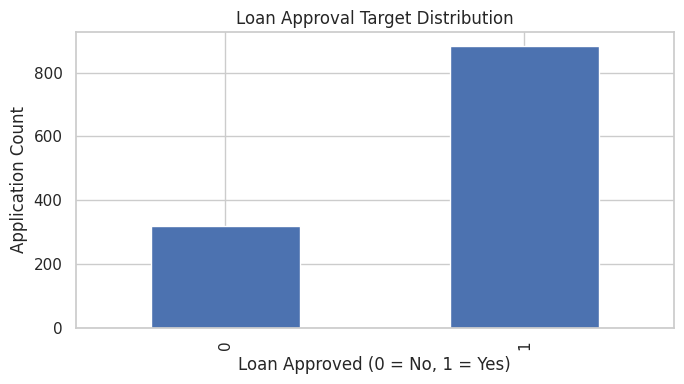

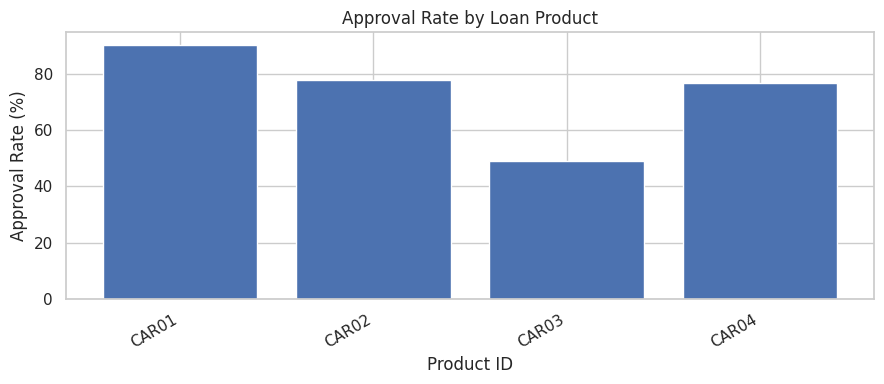

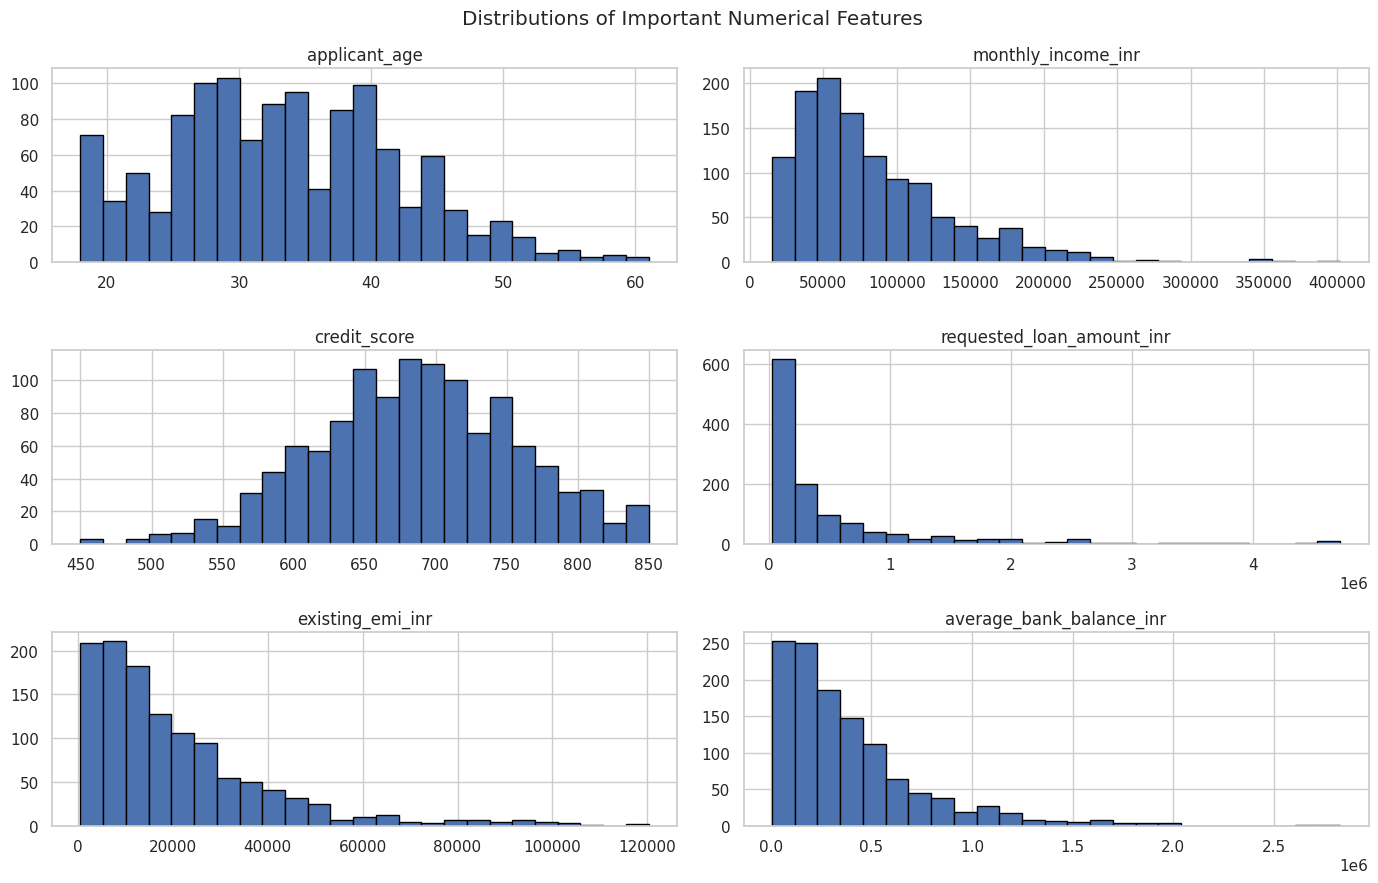

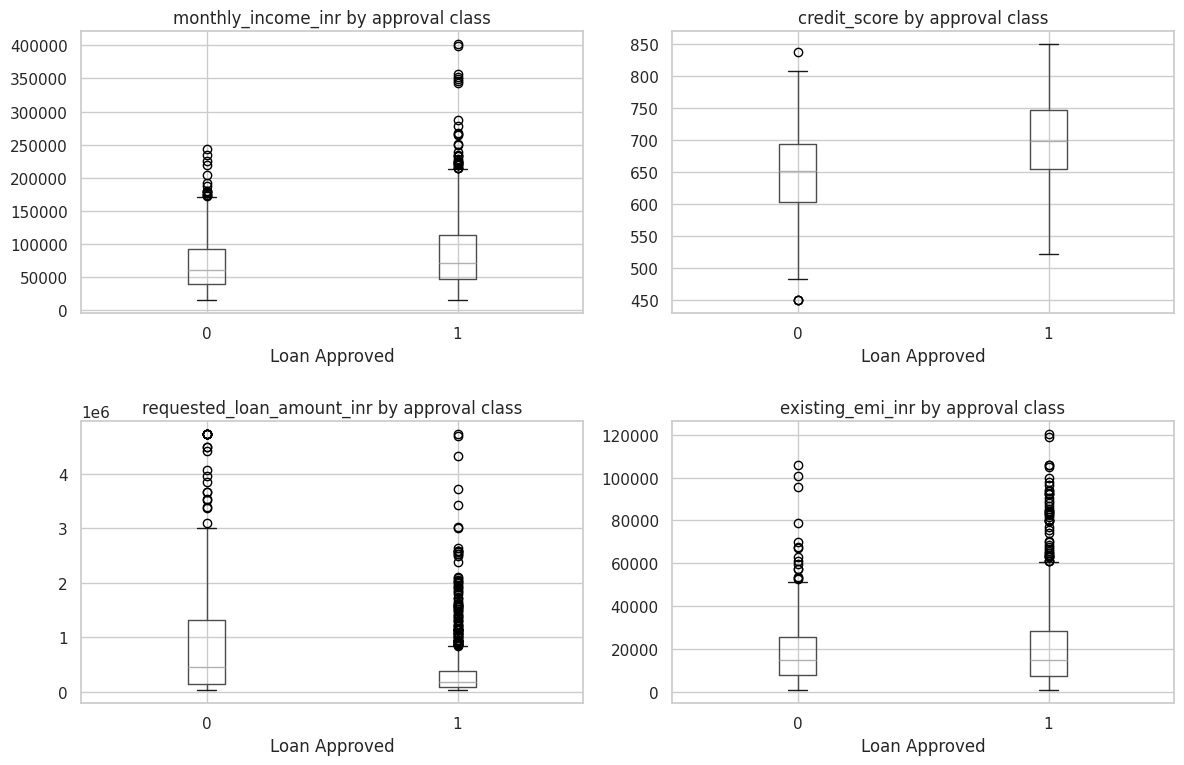

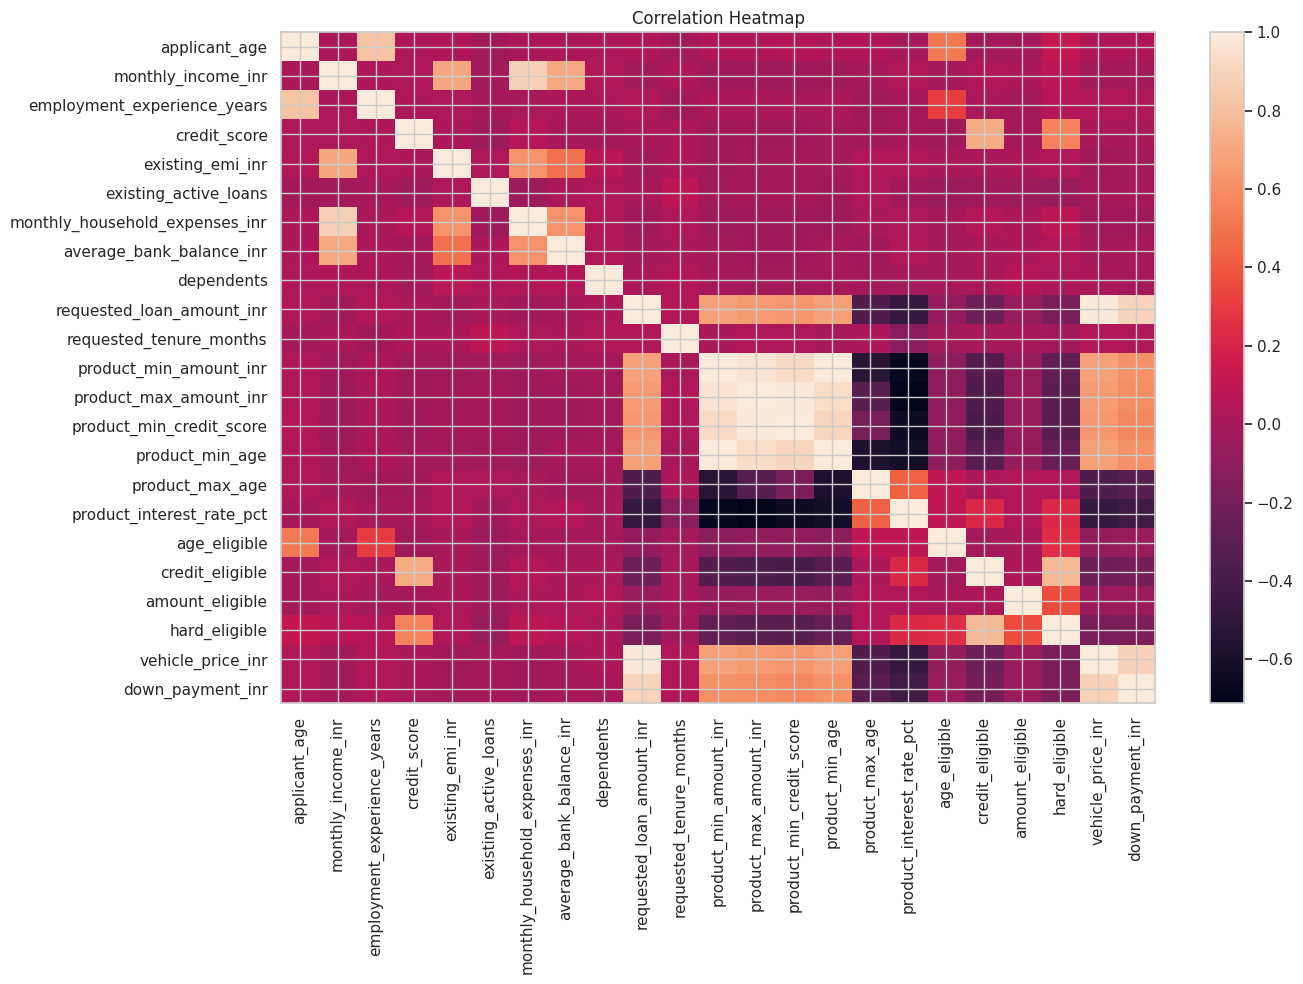

In [4]:
# 1. Target class balance
plt.figure(figsize=(7,4))
df["loan_approved"].value_counts().sort_index().plot(kind="bar")
plt.title("Loan Approval Target Distribution")
plt.xlabel("Loan Approved (0 = No, 1 = Yes)")
plt.ylabel("Application Count")
plt.tight_layout()
plt.savefig(EDA_DIR / "01_target_distribution.png", dpi=150)
plt.show()

# 2. Product-wise approval rate
plt.figure(figsize=(9,4))
plt.bar(product_table["product_id"], product_table["Approval_Rate"])
plt.title("Approval Rate by Loan Product")
plt.xlabel("Product ID")
plt.ylabel("Approval Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(EDA_DIR / "02_product_approval_rate.png", dpi=150)
plt.show()

# 3. Histograms for important numerical features
numeric_plot_cols = [c for c in ["applicant_age","monthly_income_inr","credit_score",
    "requested_loan_amount_inr","existing_emi_inr","average_bank_balance_inr"] if c in df.columns]
df[numeric_plot_cols].hist(figsize=(14,9), bins=25, edgecolor="black")
plt.suptitle("Distributions of Important Numerical Features")
plt.tight_layout()
plt.savefig(EDA_DIR / "03_numeric_distributions.png", dpi=150)
plt.show()

# 4. Boxplots compare numerical values across target classes
box_cols = [c for c in ["monthly_income_inr","credit_score","requested_loan_amount_inr","existing_emi_inr"] if c in df.columns]
fig, axes = plt.subplots(2,2,figsize=(12,8))
for col, ax in zip(box_cols, axes.flatten()):
    df.boxplot(column=col, by="loan_approved", ax=ax)
    ax.set_title(f"{col} by approval class")
    ax.set_xlabel("Loan Approved")
for ax in axes.flatten()[len(box_cols):]:
    ax.set_visible(False)
plt.suptitle("")
plt.tight_layout()
plt.savefig(EDA_DIR / "04_boxplots_by_target.png", dpi=150)
plt.show()

# 5. Correlation heatmap
corr = df.select_dtypes(include=np.number).drop(columns=["loan_approved"], errors="ignore").corr()
plt.figure(figsize=(14,10))
plt.imshow(corr, aspect="auto", interpolation="nearest")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig(EDA_DIR / "05_correlation_heatmap.png", dpi=150)
plt.show()

## Step 5 – Prepare the model features and target

`loan_approved` is the target. The unique `application_id` is an identifier and is not used as a predictive feature. We load the category's feature schema so that the columns used during training match the columns expected by the LoanIQ backend. Numeric values are imputed and scaled; categorical values are imputed and one-hot encoded.

In [5]:
with open(REPORT_DIR / "car_feature_schema.json", "r", encoding="utf-8") as f:
    feature_schema = json.load(f)
FEATURE_COLUMNS = feature_schema["feature_columns"]
X = df[FEATURE_COLUMNS].copy()
y = df["loan_approved"].astype(int).copy()

categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = [c for c in X.columns if c not in categorical_features]

print("Input features:", len(FEATURE_COLUMNS))
print("Categorical features:", categorical_features)
print("Numeric features:", len(numeric_features))

Input features: 28
Categorical features: ['product_id', 'loan_type', 'employment_type', 'vehicle_condition', 'vehicle_type']
Numeric features: 23


## Step 6 – Train/test split and preprocessing

We reserve 20% of records for testing and use 80% for training. Stratification keeps the class proportions similar in both sets. Preprocessing is placed inside a pipeline so each model receives the same transformations and inference can reuse them.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
display(pd.DataFrame({
    "Train %": y_train.value_counts(normalize=True).sort_index() * 100,
    "Test %": y_test.value_counts(normalize=True).sort_index() * 100
}).round(2))

# Dense one-hot output supports HistGradientBoosting, CatBoost and MLP in this common pipeline.
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
], sparse_threshold=0)

Training rows: 960 | Test rows: 240


,Train %,Test %
loan_approved,,
0,26.46,26.67
1,73.54,73.33


## Step 7 – Define the eight baseline algorithms

We define the eight algorithms shown in the supplied comparison reference. The settings are fixed baseline settings, not tuned parameters. Dummy is included as a simple baseline to check whether the trained models improve over a naive strategy.

CatBoost and XGBoost use GPU settings when CUDA is available. If no CUDA GPU is available, the code selects CPU mode and labels the algorithm accordingly.

In [7]:
# Determine GPU/CPU labels and configure CatBoost/XGBoost accordingly.
catboost_label = "CatBoost (GPU)" if GPU_AVAILABLE else "CatBoost (CPU fallback)"
xgboost_label = "XGBoost (GPU)" if GPU_AVAILABLE else "XGBoost (CPU fallback)"

models = {
    "Dummy": DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    catboost_label: CatBoostSklearnWrapper(
        iterations=300, depth=6, learning_rate=0.05,
        task_type="GPU" if GPU_AVAILABLE else "CPU", random_seed=RANDOM_STATE
    ),
    xgboost_label: XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.05,
        subsample=0.9, colsample_bytree=0.9, objective="binary:logistic",
        eval_metric="logloss", tree_method="hist",
        device="cuda" if GPU_AVAILABLE else "cpu",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "MLP": MLPClassifier(hidden_layer_sizes=(100,), max_iter=300, random_state=RANDOM_STATE)
}

print("Algorithms to compare:")
for model_name in models:
    print("-", model_name)
print("Count:", len(models))

Algorithms to compare:
- Dummy
- Logistic Regression
- Decision Tree
- Random Forest
- HistGradientBoosting
- CatBoost (CPU fallback)
- XGBoost (CPU fallback)
- MLP
Count: 8


## Step 8 – Train all models and calculate comparison metrics

Each model is trained on the same training set and evaluated on the same test set. We measure accuracy, precision, recall, F1-score, ROC-AUC, PR-AUC, log loss and training time in seconds. The table is sorted by ROC-AUC, matching the style of the supplied reference table.

Training time measures the `fit()` operation only; it does not include notebook startup, preprocessing setup or test prediction time.

In [8]:
comparison_rows = []
trained_pipelines = {}
prediction_cache = {}

for model_name, estimator in models.items():
    # Use a complete pipeline so preprocessing is retained with the trained model.
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", estimator)
    ])

    start_time = time.perf_counter()
    pipeline.fit(X_train, y_train)
    training_seconds = time.perf_counter() - start_time

    predicted = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    row = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predicted),
        "Precision": precision_score(y_test, predicted, zero_division=0),
        "Recall": recall_score(y_test, predicted, zero_division=0),
        "F1-Score": f1_score(y_test, predicted, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities),
        "Log Loss": log_loss(y_test, probabilities, labels=[0, 1]),
        "Time (s)": training_seconds
    }
    comparison_rows.append(row)
    trained_pipelines[model_name] = pipeline
    prediction_cache[model_name] = (predicted, probabilities)
    print(f"Completed: {model_name}")

comparison_table = pd.DataFrame(comparison_rows).sort_values(
    "ROC-AUC", ascending=False
).reset_index(drop=True)

print("Model comparison table:")
display(comparison_table.style.format({
    "Accuracy":"{:.4f}", "Precision":"{:.4f}", "Recall":"{:.4f}",
    "F1-Score":"{:.4f}", "ROC-AUC":"{:.4f}", "PR-AUC":"{:.4f}",
    "Log Loss":"{:.4f}", "Time (s)":"{:.4f}"
}))

Completed: Dummy
Completed: Logistic Regression
Completed: Decision Tree


Completed: Random Forest


Completed: HistGradientBoosting


Completed: CatBoost (CPU fallback)
Completed: XGBoost (CPU fallback)


Completed: MLP
Model comparison table:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Log Loss,Time (s)
0,CatBoost (CPU fallback),0.8000,0.8333,0.9091,0.8696,0.8352,0.9356,0.4407,0.3985
1,Random Forest,0.7833,0.8163,0.9091,0.8602,0.8260,0.9295,0.4360,0.1714
2,Logistic Regression,0.7750,0.8144,0.8977,0.8541,0.8204,0.9298,0.4446,0.0177
3,XGBoost (CPU fallback),0.7833,0.8333,0.8807,0.8564,0.8149,0.9252,0.5184,0.1619
4,HistGradientBoosting,0.7625,0.8115,0.8807,0.8447,0.8034,0.9182,0.5921,0.1908
5,MLP,0.7417,0.8132,0.8409,0.8268,0.7864,0.9041,0.6498,0.5417
6,Decision Tree,0.6875,0.7988,0.7670,0.7826,0.6179,0.7836,11.2636,0.0191
7,Dummy,0.7333,0.7333,1.0000,0.8462,0.5000,0.7333,0.5799,0.0108


## Final Model Comparison Table

The table below is the direct comparison of all eight trained algorithms. It includes every metric requested: Accuracy, Precision, Recall, F1-Score, ROC-AUC, PR-AUC, Log Loss and training Time (s). The rows are sorted by ROC-AUC.

In [9]:
# Display the complete comparison as a standard notebook table.
comparison_table_display = comparison_table.copy()
display(comparison_table_display.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Log Loss,Time (s)
0,CatBoost (CPU fallback),0.8000,0.8333,0.9091,0.8696,0.8352,0.9356,0.4407,0.3985
1,Random Forest,0.7833,0.8163,0.9091,0.8602,0.8260,0.9295,0.4360,0.1714
2,Logistic Regression,0.7750,0.8144,0.8977,0.8541,0.8204,0.9298,0.4446,0.0177
3,XGBoost (CPU fallback),0.7833,0.8333,0.8807,0.8564,0.8149,0.9252,0.5184,0.1619
4,HistGradientBoosting,0.7625,0.8115,0.8807,0.8447,0.8034,0.9182,0.5921,0.1908
5,MLP,0.7417,0.8132,0.8409,0.8268,0.7864,0.9041,0.6498,0.5417
6,Decision Tree,0.6875,0.7988,0.7670,0.7826,0.6179,0.7836,11.2636,0.0191
7,Dummy,0.7333,0.7333,1.0000,0.8462,0.5000,0.7333,0.5799,0.0108


## Step 9 – Compare models visually and inspect the best model

We plot ROC-AUC scores to make the comparison easier to interpret. The model with the highest ROC-AUC is selected for the category's saved pipeline. We then display its confusion matrix and classification report.

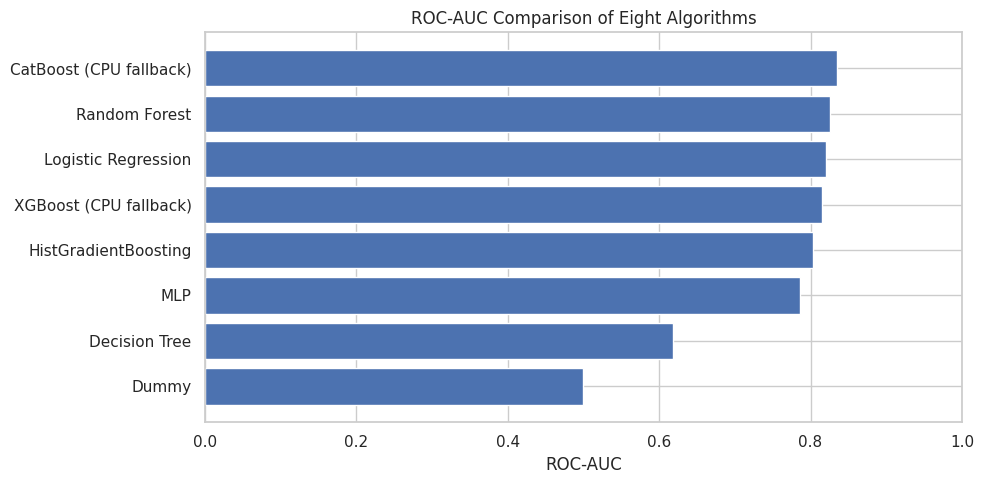

Selected model: CatBoost (CPU fallback)


,Predicted Not Approved,Predicted Approved
Actual Not Approved,32,32
Actual Approved,16,160


              precision    recall  f1-score   support

           0       0.67      0.50      0.57        64
           1       0.83      0.91      0.87       176

    accuracy                           0.80       240
   macro avg       0.75      0.70      0.72       240
weighted avg       0.79      0.80      0.79       240



In [10]:
plt.figure(figsize=(10,5))
plt.barh(comparison_table["Model"], comparison_table["ROC-AUC"])
plt.gca().invert_yaxis()
plt.xlim(0,1)
plt.xlabel("ROC-AUC")
plt.title("ROC-AUC Comparison of Eight Algorithms")
plt.tight_layout()
plt.savefig(EDA_DIR / "06_eight_model_roc_auc_comparison.png", dpi=150)
plt.show()

best_model_name = comparison_table.iloc[0]["Model"]
best_pipeline = trained_pipelines[best_model_name]
best_predictions, best_probabilities = prediction_cache[best_model_name]

print("Selected model:", best_model_name)
confusion = confusion_matrix(y_test, best_predictions)
display(pd.DataFrame(confusion,
    index=["Actual Not Approved","Actual Approved"],
    columns=["Predicted Not Approved","Predicted Approved"]))
print(classification_report(y_test, best_predictions, zero_division=0))

## Step 10 – Save the model, comparison table and metrics

We save the complete preprocessing-and-model pipeline using Joblib. We also save the full eight-model comparison table as CSV and JSON. The LoanIQ backend should load this pipeline and pass a DataFrame with the exact feature names and order from the feature schema.

In [11]:
model_path = MODEL_DIR / "car_loan_approval_model.joblib"
table_path = REPORT_DIR / "car_eight_algorithm_comparison.csv"
metrics_path = REPORT_DIR / "car_model_metrics.json"

joblib.dump(best_pipeline, model_path)
comparison_table.to_csv(table_path, index=False)

report = {
    "category": "Car",
    "selected_model": best_model_name,
    "selection_metric": "ROC-AUC",
    "algorithms_compared": comparison_table["Model"].tolist(),
    "gpu_available": bool(GPU_AVAILABLE),
    "comparison": comparison_table.to_dict(orient="records"),
    "feature_columns": FEATURE_COLUMNS,
    "training_rows": int(len(X_train)),
    "testing_rows": int(len(X_test)),
    "dataset": "car_loan_acceptance.csv",
    "synthetic_data_warning": "Metrics apply only to synthetic data and do not establish real-world lender performance."
}
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print("Saved model:", model_path)
print("Saved comparison:", table_path)
print("Saved metrics:", metrics_path)

Saved model: /mnt/data/LoanIQ_retrained_ml_package/models/car_loan_approval_model.joblib
Saved comparison: /mnt/data/LoanIQ_retrained_ml_package/reports/car_eight_algorithm_comparison.csv
Saved metrics: /mnt/data/LoanIQ_retrained_ml_package/reports/car_model_metrics.json


## Step 11 – Conclusion

In this practical, we performed EDA using tables and graphs, prepared the dataset, and trained eight baseline classification algorithms. We compared them using accuracy, precision, recall, F1-score, ROC-AUC, PR-AUC, log loss and training time.

The comparison table identifies the strongest ROC-AUC result for this category. The selected model pipeline is saved for LoanIQ V2. Dummy provides a baseline against which the machine-learning algorithms can be judged.

The results are limited to this synthetic dataset. They do not demonstrate actual lender decision accuracy. For a real lending application, validation on consented real-world data, external testing, probability calibration, fairness analysis and monitoring would be necessary.

**Model-selection caveat:** this notebook uses the test set to compare and select the best of the eight algorithms. The resulting score is useful for this educational comparison but is not an unbiased final performance estimate. A separate validation set should be used for model selection in a rigorous evaluation.